# Tugas Kelompok 2: Optimasi Model CNN (Hyperparameter Tuning)
**Mata Kuliah:** Artificial Intelligence — Kelas JWCA — Kelompok 4

**Asysyifa Isharul Jannah (2902692604)**

**Alur notebook:**
1. Load & preprocessing data CIFAR-10
2. Training model awal (baseline dari TK1)
3. Hyperparameter tuning dengan Keras Tuner (RandomSearch)
4. Training ulang model dengan hyperparameter terbaik
5. Transfer learning MobileNetV2
6. Evaluasi & perbandingan baseline, tuning dan transfer learning
7. Simpan model terbaik sebagai `model.keras` untuk aplikasi Streamlit

> Runtime T4 GPU. Total waktu sekitar 45–60 menit.

## 1. Load & Preprocessing Data

In [1]:
!pip install -q datasets keras-tuner

import os, random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers
import keras_tuner as kt
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from sklearn.metrics import classification_report, confusion_matrix

# Seed agar hasil lebih konsisten antar-run
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

dataset = load_dataset("uoft-cs/cifar10")

x_train_all = np.array([np.array(img) for img in dataset['train']['img']])
y_train_all = np.array(dataset['train']['label']).reshape(-1, 1)
x_test_raw  = np.array([np.array(img) for img in dataset['test']['img']])
y_test_raw  = np.array(dataset['test']['label']).reshape(-1, 1)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

VAL_SIZE = 10000
x_val_raw,   y_val_raw   = x_train_all[-VAL_SIZE:], y_train_all[-VAL_SIZE:]
x_train_raw, y_train_raw = x_train_all[:-VAL_SIZE], y_train_all[:-VAL_SIZE]

# Normalisasi 0–1 (aplikasi Streamlit memakai NORMALIZATION = "rescale")
x_train = x_train_raw.astype('float32') / 255.0
x_val   = x_val_raw.astype('float32') / 255.0
x_test  = x_test_raw.astype('float32') / 255.0

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1)
], name="data_augmentation")

BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (tf.data.Dataset.from_tensor_slices((x_train, y_train_raw))
            .shuffle(10000, seed=SEED)
            .batch(BATCH_SIZE)
            .map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
            .prefetch(AUTOTUNE))
val_ds  = tf.data.Dataset.from_tensor_slices((x_val, y_val_raw)).batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test_raw)).batch(BATCH_SIZE).prefetch(AUTOTUNE)

print(f"Data Training  : {len(x_train):,} sampel")
print(f"Data Validasi  : {len(x_val):,} sampel")
print(f"Data Testing   : {len(x_test):,} sampel")
print(f"Dimensi Input  : {x_train.shape[1:]}")
print(f"Rentang Piksel : [{x_train.min():.1f}, {x_train.max():.1f}]")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 5.3 MB/s eta 0:00:00


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Data Training  : 40,000 sampel
Data Validasi  : 10,000 sampel
Data Testing   : 10,000 sampel
Dimensi Input  : (32, 32, 3)
Rentang Piksel : [0.0, 1.0]


## 2. Model Awal (Baseline dari TK1)
Model ini menjadi pembanding. Hasil tuning dianggap berhasil jika akurasinya lebih tinggi dari baseline.

In [2]:
def build_baseline():
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(len(class_names), activation='softmax')
    ], name='cnn_baseline')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def make_callbacks(ckpt_path, patience=6):
    return [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience,
                                         restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3,
                                             min_lr=1e-6, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(ckpt_path, monitor='val_accuracy',
                                           save_best_only=True, verbose=0),
    ]

EPOCHS = 40

baseline = build_baseline()
baseline.summary()
history_base = baseline.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                            callbacks=make_callbacks('baseline.keras'), verbose=1)

base_test_loss, base_test_acc = baseline.evaluate(test_ds, verbose=0)
base_val_acc = max(history_base.history['val_accuracy'])
print(f"\nBaseline -> best val_accuracy: {base_val_acc:.4f} | test_accuracy: {base_test_acc:.4f}")

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 23s 23ms/step - accuracy: 0.3388 - loss: 1.7974 - val_accuracy: 0.4600 - val_loss: 1.5047 - learning_rate: 0.0010
Epoch 2/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.4572 - loss: 1.5049 - val_accuracy: 0.5397 - val_loss: 1.2570 - learning_rate: 0.0010
Epoch 3/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - accuracy: 0.5037 - loss: 1.3829 - val_accuracy: 0.5399 - val_loss: 1.2588 - learning_rate: 0.0010
Epoch 4/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 20ms/step - accuracy: 0.5314 - loss: 1.3097 - val_accuracy: 0.5925 - val_loss: 1.1481 - learning_rate: 0.0010
Epoch 5/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - accuracy: 0.5553 - loss: 1.2453 - val_accuracy: 0.6097 - val_loss: 1.1220 - learning_rate: 0.0010
Epoch 6/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - accuracy: 0.5756 - loss: 1.2001 - val_accuracy: 0.6504 - val_loss: 0.9817 - learning_rate: 0.0010
Epoch 7/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 19ms/step - accuracy: 0.5896 - l

## 3. Hyperparameter Tuning (Keras Tuner — RandomSearch)

**Perbaikan dibanding versi sebelumnya:**
- Model tuning kini memiliki **3 blok konvolusi** (sebelumnya hanya 2, sehingga lebih sederhana dari baseline).
- **Batch Normalization** ikut diuji (dipakai / tidak).
- Jumlah kombinasi dinaikkan dari 3 menjadi **10 trial**.
- `overwrite=True` agar tuning benar-benar dijalankan ulang, bukan memuat hasil lama.

| Hyperparameter | Nilai yang diuji |
|---|---|
| Filter blok 1 | 32, 64 |
| Filter blok 2 | 64, 128 |
| Filter blok 3 | 128, 256 |
| Batch Normalization | Ya / Tidak |
| Dense units | 128, 256 |
| Dropout | 0.2 – 0.5 |
| Learning rate | 0.001, 0.0005, 0.0001 |

In [3]:
def build_model(hp):
    use_bn = hp.Boolean('batch_norm')
    model = tf.keras.Sequential(name='cnn_tuned')
    model.add(tf.keras.Input(shape=(32, 32, 3)))

    for i, choices in enumerate([[32, 64], [64, 128], [128, 256]], start=1):
        model.add(layers.Conv2D(hp.Choice(f'filters_{i}', choices), (3, 3), padding='same'))
        if use_bn:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation('relu'))
        model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(hp.Choice('units', [128, 256]), activation='relu'))
    model.add(layers.Dropout(hp.Float('dropout', 0.2, 0.5, step=0.1)))
    model.add(layers.Dense(len(class_names), activation='softmax'))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=hp.Choice('learning_rate', [1e-3, 5e-4, 1e-4])),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'])
    return model

MAX_TRIALS = 10        # kurangi ke 6 jika waktu Colab terbatas
SEARCH_EPOCHS = 12     # epoch per trial saat pencarian

tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=MAX_TRIALS,
    executions_per_trial=1,
    directory='cifar10_tuning',
    project_name='cnn_cifar10_tk2',
    overwrite=True,
    seed=SEED,
)
tuner.search_space_summary()

tuner.search(train_ds, validation_data=val_ds, epochs=SEARCH_EPOCHS,
             callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3,
                                                         restore_best_weights=True)],
             verbose=1)

Trial 10 Complete [00h 02m 26s]
val_accuracy: 0.5127999782562256

Best val_accuracy So Far: 0.7150999903678894
Total elapsed time: 00h 28m 33s


### 3.1 Tabel Hasil Semua Trial (untuk Bab II laporan)

In [4]:
rows = []
for t in tuner.oracle.get_best_trials(num_trials=MAX_TRIALS):
    hp = t.hyperparameters.values
    rows.append({
        'Trial': t.trial_id,
        'Filter 1': hp['filters_1'], 'Filter 2': hp['filters_2'], 'Filter 3': hp['filters_3'],
        'BatchNorm': 'Ya' if hp['batch_norm'] else 'Tidak',
        'Dense': hp['units'], 'Dropout': round(hp['dropout'], 1),
        'Learning rate': hp['learning_rate'],
        'Val accuracy': round(t.score, 4) if t.score is not None else None,
    })
trials_df = pd.DataFrame(rows).sort_values('Val accuracy', ascending=False).reset_index(drop=True)
trials_df.index = trials_df.index + 1
trials_df.to_csv('hasil_tuning.csv', index_label='Peringkat')
display(trials_df)

best_hps = tuner.get_best_hyperparameters(1)[0]
print("\nHYPERPARAMETER TERBAIK:")
for k, v in best_hps.values.items():
    print(f"  - {k:<14}: {v}")

,Trial,Filter 1,Filter 2,Filter 3,BatchNorm,Dense,Dropout,Learning rate,Val accuracy
1,01,32,64,256,Tidak,256,0.4,0.0010,0.7151
2,06,32,128,256,Tidak,256,0.3,0.0010,0.7130
3,05,32,128,128,Ya,128,0.2,0.0010,0.6978
4,04,64,64,128,Ya,256,0.2,0.0005,0.6666
5,00,32,64,128,Ya,256,0.3,0.0005,0.6597
6,08,64,64,128,Ya,128,0.4,0.0001,0.5705
7,02,32,128,128,Ya,128,0.3,0.0001,0.5487
8,09,32,64,256,Tidak,256,0.2,0.0001,0.5128
9,07,32,64,256,Tidak,128,0.4,0.0001,0.4990
10,03,32,64,128,Tidak,128,0.4,0.0001,0.4470



HYPERPARAMETER TERBAIK:
  - batch_norm    : False
  - filters_1     : 32
  - filters_2     : 64
  - filters_3     : 256
  - units         : 256
  - dropout       : 0.4
  - learning_rate : 0.001


## 4. Training Ulang Model dengan Hyperparameter Terbaik

Model: "cnn_tuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 256)      │       147,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,218,506 (4.65 MB)

 Trainable params: 1,218,506 (4.65 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.3522 - loss: 1.7652 - val_accuracy: 0.4420 - val_loss: 1.5516 - learning_rate: 0.0010
Epoch 2/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - accuracy: 0.4722 - loss: 1.4704 - val_accuracy: 0.5352 - val_loss: 1.3134 - learning_rate: 0.0010
Epoch 3/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 19ms/step - accuracy: 0.5153 - loss: 1.3557 - val_accuracy: 0.5876 - val_loss: 1.1435 - learning_rate: 0.0010
Epoch 4/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.5451 - loss: 1.2739 - val_accuracy: 0.6190 - val_loss: 1.0678 - learning_rate: 0.0010
Epoch 5/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.5667 - loss: 1.2189 - val_accuracy: 0.6174 - val_loss: 1.0945 - learning_rate: 0.0010
Epoch 6/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 19ms/step - accuracy: 0.5883 - loss: 1.1703 - val_accuracy: 0.6432 - val_loss: 0.9854 - learning_rate: 0.0010
Epoch 7/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 19ms/step - accuracy: 0.6079 - l

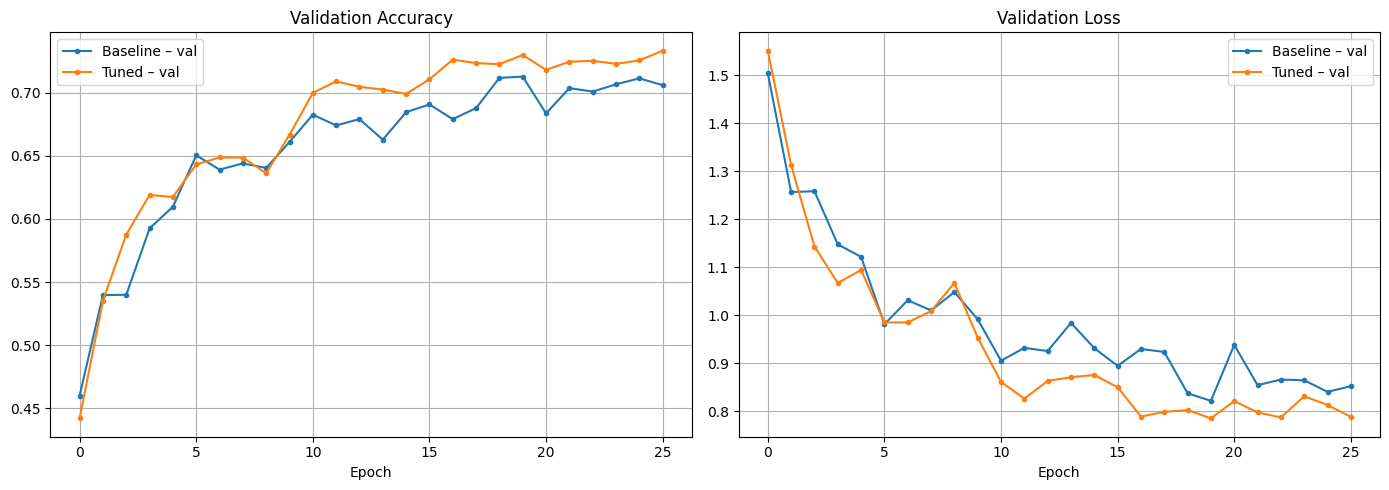

In [5]:
tuned = tuner.hypermodel.build(best_hps)
tuned.summary()
history_tuned = tuned.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                          callbacks=make_callbacks('tuned.keras'), verbose=1)

tuned_test_loss, tuned_test_acc = tuned.evaluate(test_ds, verbose=0)
tuned_val_acc = max(history_tuned.history['val_accuracy'])
print(f"\nTuned -> best val_accuracy: {tuned_val_acc:.4f} | test_accuracy: {tuned_test_acc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for h, name in [(history_base, 'Baseline'), (history_tuned, 'Tuned')]:
    axes[0].plot(h.history['val_accuracy'], marker='o', markersize=3, label=f'{name} – val')
    axes[1].plot(h.history['val_loss'], marker='o', markersize=3, label=f'{name} – val')
axes[0].set_title('Validation Accuracy'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True)
axes[1].set_title('Validation Loss');     axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.savefig('perbandingan_training.png', dpi=150, bbox_inches='tight'); plt.show()

## 4.1 Transfer Learning dengan MobileNetV2

In [6]:
TRANSFER_HEAD_EPOCHS = 12
TRANSFER_FINETUNE_EPOCHS = 10


def build_transfer_model():
    backbone = tf.keras.applications.MobileNetV2(
        input_shape=(96, 96, 3),
        include_top=False,
        weights='imagenet')
    backbone.trainable = False

    inputs = tf.keras.Input(shape=(32, 32, 3), name='cifar10_image')
    x = layers.Resizing(96, 96, name='resize_for_mobilenet')(inputs)
    x = layers.Rescaling(2.0, offset=-1.0, name='mobilenet_preprocessing')(x)
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(len(class_names), activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs, name='mobilenetv2_transfer')
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'])
    return model, backbone


transfer_model, transfer_backbone = build_transfer_model()
transfer_model.summary()
history_transfer_head = transfer_model.fit(
    train_ds, validation_data=val_ds, epochs=TRANSFER_HEAD_EPOCHS,
    callbacks=make_callbacks('transfer_head.keras', patience=4), verbose=1)

_, transfer_head_val_acc = transfer_model.evaluate(val_ds, verbose=0)
transfer_head_weights = transfer_model.get_weights()

transfer_backbone.trainable = True
for layer in transfer_backbone.layers[:-30]:
    layer.trainable = False
for layer in transfer_backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])
history_transfer_finetune = transfer_model.fit(
    train_ds, validation_data=val_ds, epochs=TRANSFER_FINETUNE_EPOCHS,
    callbacks=make_callbacks('transfer_finetuned.keras', patience=4), verbose=1)

_, transfer_finetune_val_acc = transfer_model.evaluate(val_ds, verbose=0)
if transfer_head_val_acc > transfer_finetune_val_acc:
    transfer_model.set_weights(transfer_head_weights)
    transfer_val_acc = transfer_head_val_acc
else:
    transfer_val_acc = transfer_finetune_val_acc

transfer_test_loss, transfer_test_acc = transfer_model.evaluate(test_ds, verbose=0)
print(f"Transfer Learning -> val_accuracy: {transfer_val_acc:.4f} | test_accuracy: {transfer_test_acc:.4f}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cifar10_image (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resize_for_mobilenet (Resizing) │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 96, 96, 3)      │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,275,914 (8.68 MB)

 Trainable params: 15,370 (60.04 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

Epoch 1/12
625/625 ━━━━━━━━━━━━━━━━━━━━ 35s 37ms/step - accuracy: 0.5233 - loss: 1.4405 - val_accuracy: 0.7409 - val_loss: 0.8363 - learning_rate: 0.0010
Epoch 2/12
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.6026 - loss: 1.1610 - val_accuracy: 0.7604 - val_loss: 0.7492 - learning_rate: 0.0010
Epoch 3/12
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.6094 - loss: 1.1275 - val_accuracy: 0.7655 - val_loss: 0.7376 - learning_rate: 0.0010
Epoch 4/12
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.6172 - loss: 1.1098 - val_accuracy: 0.7576 - val_loss: 0.7685 - learning_rate: 0.0010
Epoch 5/12
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.6175 - loss: 1.1073 - val_accuracy: 0.7661 - val_loss: 0.7419 - learning_rate: 0.0010
Epoch 6/12
623/625 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6189 - loss: 1.1022
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.6154 - los

## 5. Evaluasi & Perbandingan Baseline, Tuned dan Transfer Learning

,Model,Best val accuracy,Test accuracy,Test loss,Jumlah parameter
0,Baseline (TK1),0.7128,0.7133,0.8300,356810
1,Hasil tuning,0.7333,0.7229,0.8077,1218506
2,Transfer learning MobileNetV2,0.8496,0.8441,0.4718,2275914


Selisih test accuracy (tuned - baseline): +0.96 poin persen
Model final yang dipakai di aplikasi: Transfer learning MobileNetV2

Classification report model final:
              precision    recall  f1-score   support

    airplane     0.8352    0.8920    0.8627      1000
  automobile     0.8978    0.9580    0.9269      1000
        bird     0.9056    0.7390    0.8139      1000
         cat     0.7604    0.6920    0.7246      1000
        deer     0.8860    0.7460    0.8100      1000
         dog     0.8205    0.7590    0.7886      1000
        frog     0.7772    0.9350    0.8488      1000
       horse     0.8036    0.9000    0.8491      1000
        ship     0.9161    0.8950    0.9054      1000
       truck     0.8629    0.9250    0.8929      1000

    accuracy                         0.8441     10000
   macro avg     0.8465    0.8441    0.8423     10000
weighted avg     0.8465    0.8441    0.8423     10000



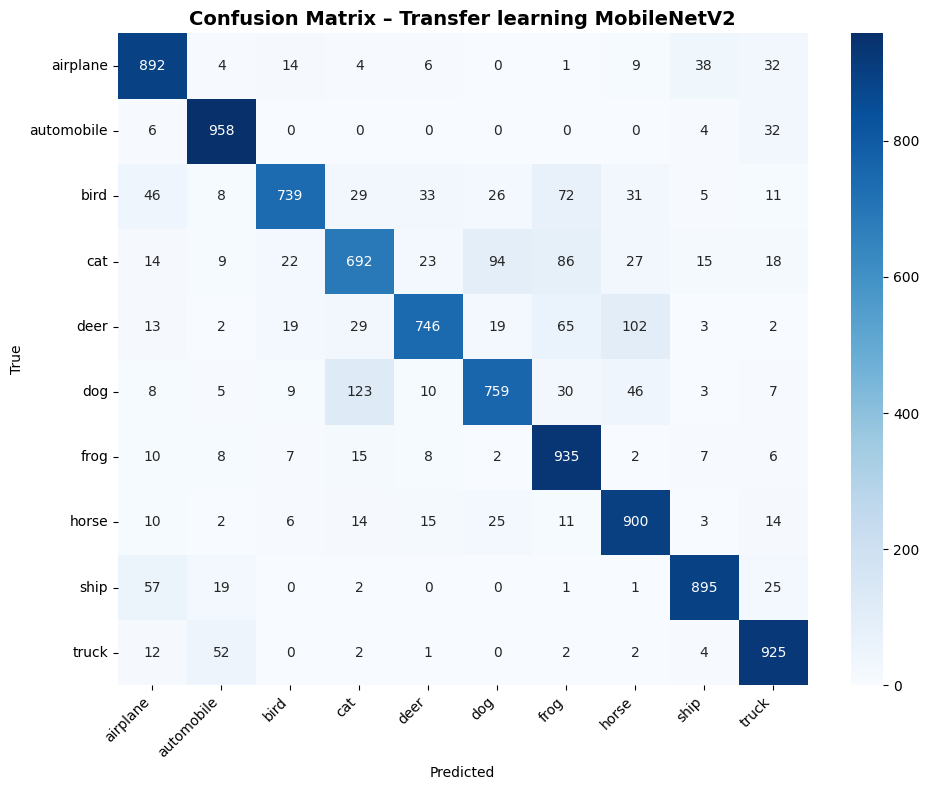

In [7]:
compare_df = pd.DataFrame({
    'Model': ['Baseline (TK1)', 'Hasil tuning', 'Transfer learning MobileNetV2'],
    'Best val accuracy': [round(base_val_acc, 4), round(tuned_val_acc, 4), round(transfer_val_acc, 4)],
    'Test accuracy': [round(base_test_acc, 4), round(tuned_test_acc, 4), round(transfer_test_acc, 4)],
    'Test loss': [round(base_test_loss, 4), round(tuned_test_loss, 4), round(transfer_test_loss, 4)],
    'Jumlah parameter': [baseline.count_params(), tuned.count_params(), transfer_model.count_params()],
})
display(compare_df)
compare_df.to_csv('perbandingan_model.csv', index=False)

diff = (tuned_test_acc - base_test_acc) * 100
print(f"Selisih test accuracy (tuned - baseline): {diff:+.2f} poin persen")

# Pilih model final berdasarkan validation accuracy (test set hanya untuk pelaporan)
candidates = {
    'Baseline (TK1)': (baseline, base_val_acc),
    'Hasil tuning': (tuned, tuned_val_acc),
    'Transfer learning MobileNetV2': (transfer_model, transfer_val_acc),
}
final_name = max(candidates, key=lambda name: candidates[name][1])
final_model = candidates[final_name][0]
print(f"Model final yang dipakai di aplikasi: {final_name}")

y_true = y_test_raw.flatten()
y_pred = np.argmax(final_model.predict(test_ds, verbose=0), axis=1)
print("\nClassification report model final:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix – {final_name}', fontsize=14, fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('True'); plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight'); plt.show()

## 6. Simpan Model untuk Aplikasi Streamlit
File `model.keras` di-upload ke folder `model/` di GitHub (menimpa model dummy).

In [8]:
final_model.save('model.keras')
size_mb = os.path.getsize('model.keras') / 1e6
print(f"Tersimpan: model.keras ({size_mb:.1f} MB)")
print("Upload via browser GitHub OK" if size_mb < 25 else "Lebih dari 25 MB: upload lewat GitHub Desktop")

print("\nKonfigurasi untuk app.py:")
print(f"IMG_SIZE = {tuple(final_model.input_shape[1:3])}")
print(f"CLASS_NAMES = {class_names}")
print('NORMALIZATION = "rescale"')

# Download file penting (khusus Google Colab)
try:
    from google.colab import files
    for f in ['model.keras', 'hasil_tuning.csv', 'perbandingan_model.csv',
              'perbandingan_training.png', 'confusion_matrix.png']:
        files.download(f)
except ImportError:
    print("Bukan di Colab: ambil file dari folder kerja secara manual.")

Tersimpan: model.keras (21.9 MB)
Upload via browser GitHub OK

Konfigurasi untuk app.py:
IMG_SIZE = (32, 32)
CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
NORMALIZATION = "rescale"


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>